# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import UCASAODDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects witn bounding boxes

Total number of patches: 1510


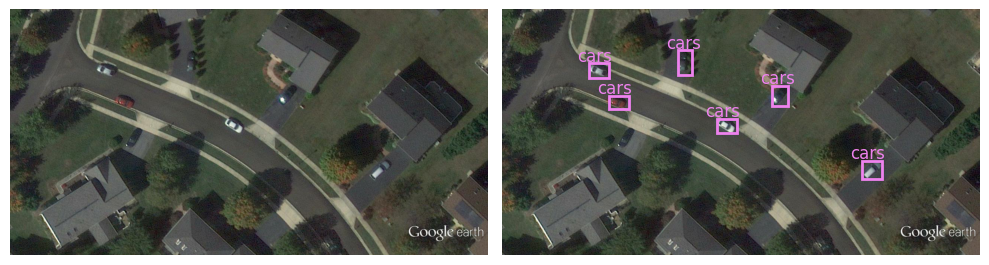

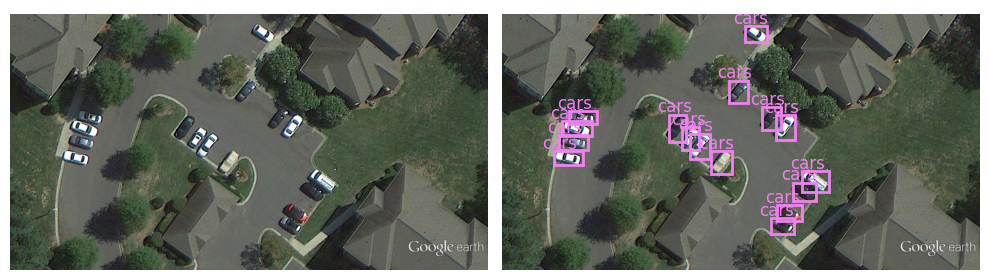

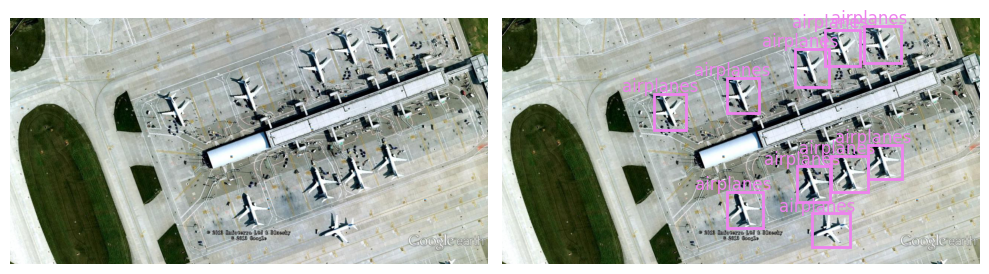

In [ ]:
dataset_config = {
    "data_dir": "./data/UCAS-AOD/images/",
    "annotation_dir": "./data/UCAS-AOD/labels/",
}
dataset = UCASAODDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(5);
dataset.show_image(10);
dataset.show_image(100);

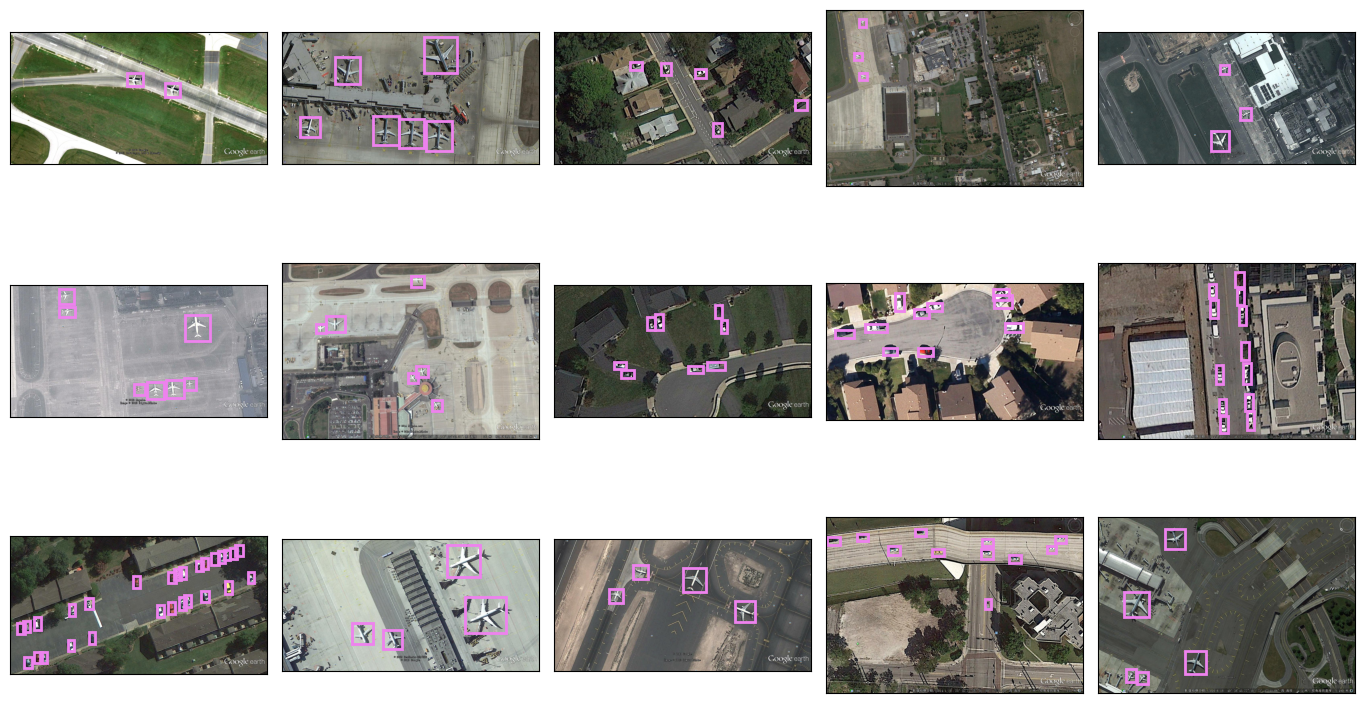

In [9]:
dataset.show_batch(15);

In [10]:
dataset.data_distribution_table()

,Label,Count
0,cars,7115
1,airplanes,7482


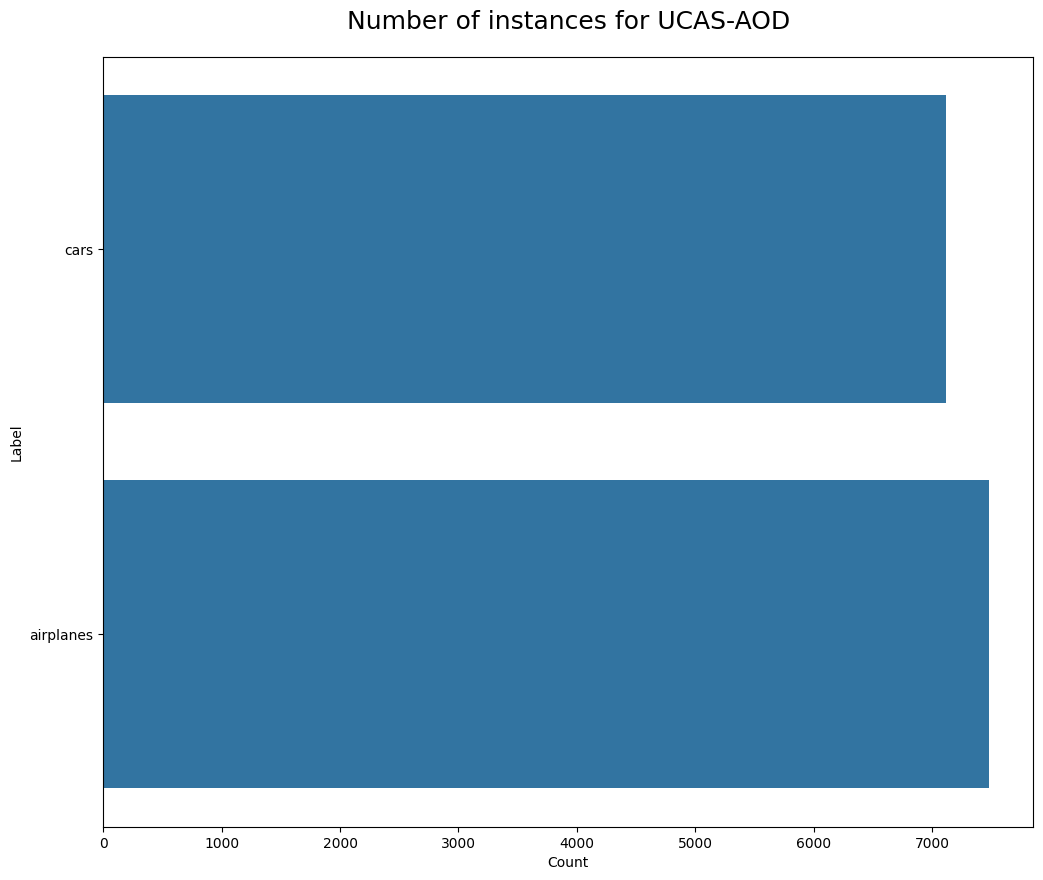

In [11]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/UCAS-AOD/images/",
    "annotation_dir": "./data/UCAS-AOD/labels/",
    "csv_file":"./data/UCAS-AOD/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = UCASAODDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1208


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/UCAS-AOD/experiments/"
model_config = {
    "num_classes": 3,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [28]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-28 09:14:20,715 INFO Starting training.
training: 100%|██████████| 151/151 [00:49<00:00,  3.03it/s]
2025-04-28 09:15:10,512 INFO epoch: 1, time: 50, loss:  0.49189
testing on train set: 100%|██████████| 151/151 [00:27<00:00,  5.50it/s]
2025-04-28 09:15:47,458 INFO map:0.617178201675415, map_50:0.9649931788444519, map_75:0.7238188982009888, map_small:0.5987419486045837, map_medium:0.6363485455513, map_large:0.8260241150856018, mar_1:0.07596325129270554, mar_10:0.5145041346549988, mar_100:0.6891328692436218, mar_small:0.6706179976463318, mar_medium:0.7050553560256958, mar_large:0.8500000238418579, map_per_class:tensor(0.5492), tensor(0.6852), mar_100_per_class:tensor(0.6381), tensor(0.7402), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)
training: 100%|██████████| 151/151 [00:49<00:00,  3.04it/s]
2025-04-28 09:16:37,181 INFO epoch: 2, time: 50, loss:  0.34221
testing on train set: 100%|██████████| 151/151 [00:26<00:00,  5.69it/s]
2025-04-28 09:17:11,761 INFO m

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/UCAS-AOD/images/",
    "annotation_dir": "./data/UCAS-AOD/labels/",
    "csv_file":"./data/UCAS-AOD/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = UCASAODDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/UCAS-AOD/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 151


2025-04-28 09:28:30,271 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UCAS-AOD/experiments/checkpoint.pth.tar
2025-04-28 09:28:30,591 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UCAS-AOD/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 19/19 [00:04<00:00,  4.52it/s]


[{'map': 0.5981762409210205,
  'map_50': 0.9358688592910767,
  'map_75': 0.7071369886398315,
  'map_small': 0.5842726826667786,
  'map_medium': 0.6339109539985657,
  'map_large': 0.9252475500106812,
  'mar_1': 0.06861056387424469,
  'mar_10': 0.4717661142349243,
  'mar_100': 0.6649542450904846,
  'mar_small': 0.6464689373970032,
  'mar_medium': 0.7052271366119385,
  'mar_large': 0.949999988079071,
  'map_per_class': [tensor(0.5301), tensor(0.6663)],
  'mar_100_per_class': [tensor(0.6058), tensor(0.7241)],
  'classes': [tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32)]}]

## Predictions

2025-04-28 09:28:36,319 INFO Loading checkpoint /home/dragik/data/FAIR_EO/UCAS-AOD/experiments/checkpoint.pth.tar
2025-04-28 09:28:36,641 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/UCAS-AOD/experiments/checkpoint.pth.tar at epoch 11


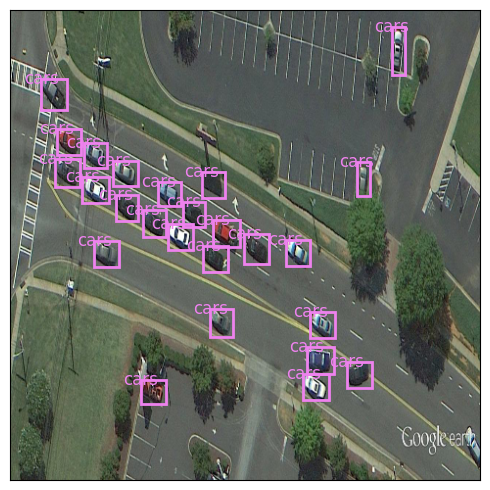

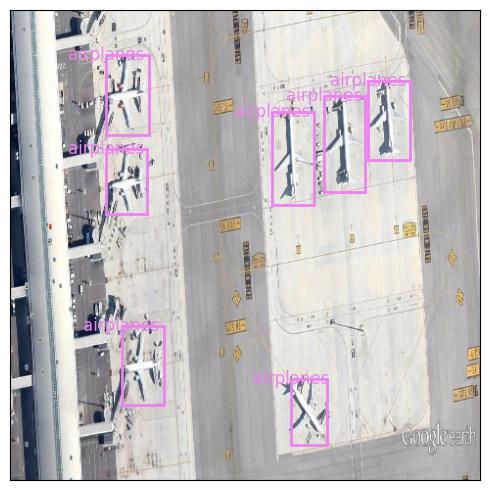

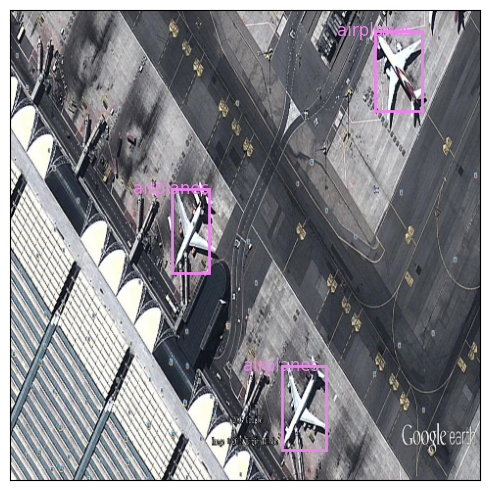

In [ ]:
model_config = {
    "num_classes": 3,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/UCAS-AOD/experiments/checkpoint.pth.tar"
labels = ["no-data","cars", "airplanes"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/UCAS-AOD/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/UCAS-AOD/' + test_list[4])
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/UCAS-AOD/' + test_list[3])
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/UCAS-AOD/' + test_list[9])
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)